# Circuit construction and noise modelling

This notebook illustrates the basic circuit API, including gate
construction, circuit manipulation, and exact simulation. 

It also introduces the noise framework based on random Weyl errors and shows how noisy
circuits can be simulated both exactly and via Pauli/Weyl-frame sampling.

Further circuit and noise functionality is documented in the full library
documentation and other examples.

In [1]:
import numpy as np
import quickqudits as qq

## Create a circuit, add gates, basic properties

In [2]:
n, d = 3, 6
qc = qq.QuantumCircuit(n, d, name="demo")

# Single-qudit gates
qc.Y(0)
qc.H(1)
qc.Y(2)
qc.Zdag(2)

# Two-qudit gate
qc.CNOT(1, 2)

print(qc)
print(repr(qc))
print("size:", qc.size)
print("depth:", qc.depth)

# You can also iterate over operations (gate, qudits, dagger_flag)
for gate, qudits, dagger in qc:
    print(gate.name, qudits, "dagger" if dagger else "")


<QuantumCircuit: name='demo', n=3, d=6, size=5, depth=3>
QuantumCircuit(num_qudits=3, dim=6, name='demo', size=5, depth=3)
size: 5
depth: 3
Y (0,) 
H (1,) 
Y (2,) 
Z (2,) dagger
CNOT (1, 2) 


## Draw the circuit

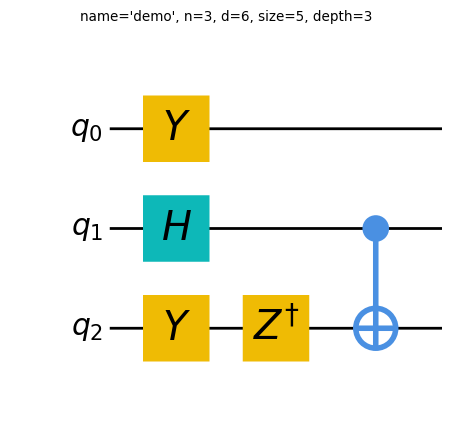

In [3]:
qc.draw(show_info=True)

In [4]:
# Statevector simulation (exact)
psi, _ = qc.execute(print_state=False)
p_sv = np.abs(psi) ** 2
print("statevector probs sum:", p_sv.sum())

# Density matrix simulation (exact)
rho = qc.copy().execute_density_matrix()
p_dm = qq.utils.density_matrix_to_probvector(rho)
print("density-matrix probs sum:", p_dm.sum())

print("SV and DM match:", np.allclose(p_sv, p_dm, atol=1e-12, rtol=0))

statevector probs sum: 1.0
density-matrix probs sum: 1.0000000000000004
SV and DM match: True


## Compose/Reverse

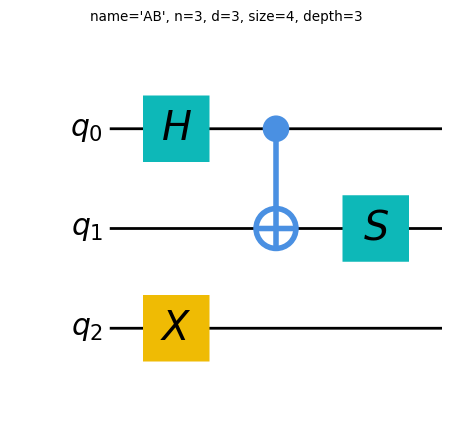

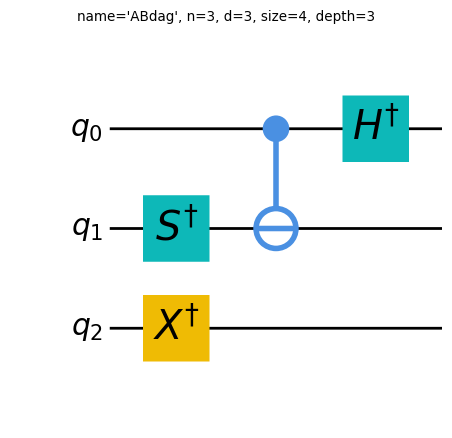

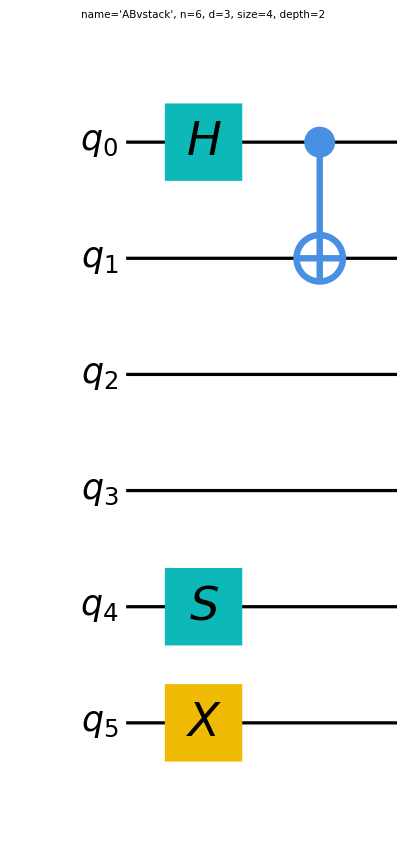

In [5]:
n, d = 3, 3
qa = qq.QuantumCircuit(n, d, name="A")
qa.H(0); qa.CNOT(0, 1)

qb = qq.QuantumCircuit(n, d, name="B")
qb.S(1); qb.X(2)

# Append B after A
q_ab = qa.compose(qb, in_place=False)
q_ab.name = "AB"
q_ab.draw(show_info=True)

# Reverse (dagger + reverse order)
q_inv = q_ab.reverse(in_place=False)
q_inv.name = "ABdag"
q_inv.draw(show_info=True)

# Compose vertically (stack qudits)
q_stack = qa.compose_vertical(qb, in_place=False)
q_stack.name = "ABvstack"
q_stack.draw(show_info=True)

## Insert gate

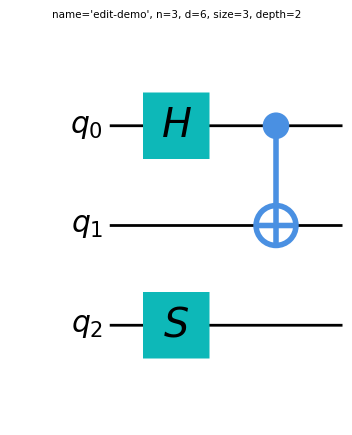

In [6]:
n, d = 3, 6
qc_ = qq.QuantumCircuit(n, d, name="edit-demo")
qc_.H(0)
qc_.CNOT(0, 1)
qc_.S(2)

qc_.draw(show_info=True)

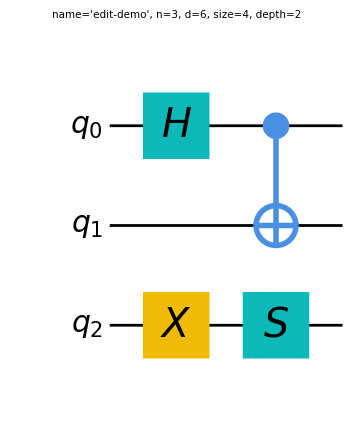

In [7]:
# Insert X on qudit 2 as the new first operation
qc_.insert(gate=qq.X_gate, qudits=(2,), column=0)
qc_.draw(show_info=True)

## Delete gate

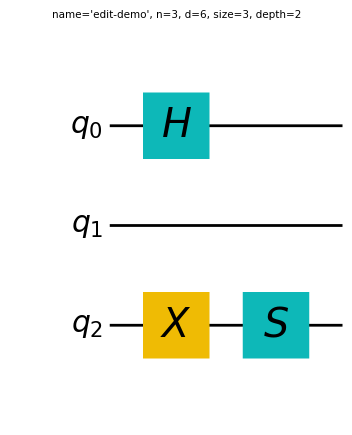

In [8]:
# delete CNOT
qc_.delete(qudit=0, column=1)
qc_.draw(show_info=True)

## Replace gate

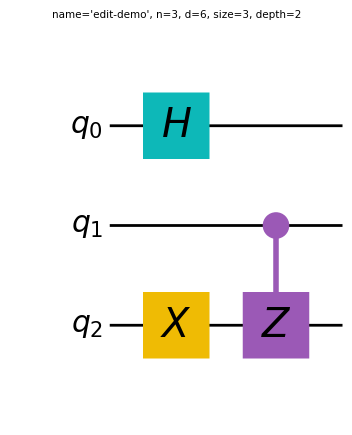

In [9]:
# replace S gate
qc_.replace(qq.CZ_gate, qudits=[1, 2], column=1)
qc_.draw(show_info=True)

## Noise modeling in this library

Noise is represented as a random Weyl error applied at certain points.

For dimension $d$, there are $d^2$ Weyl operators $W_{a,b}$ with  
$a, b \in \{0, \ldots, d-1\}$.

A noise model is a probability distribution $P[a,b]$:

- $P[0,0]$ = probability of no error  
- $P[a,b]$ for other $(a,b)$ = probability of applying error $W_{a,b}$

You can specify the model as:

1. **A scalar** $p$: *isotropic noise*  
   (“with probability $p$, apply a random non-identity Weyl error uniformly”)

2. **A full $(d,d)$ matrix** $P$ with arbitrary probabilities  
   (normalized automatically)

Internally, the circuit stores these models in a **noise registry** and inserts
lightweight `NoiseChannel` placeholders that reference a model ID.

The opacity of `NoiseChannel` placeholders corresponds to the probability of error on that channel.

The higher it is, the higher the error probability.

## Add a single noise channel

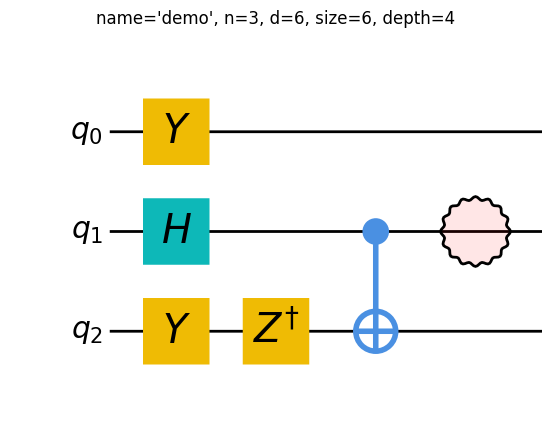

In [10]:
qc1 = qc.copy()

# Add a noise channel acting on one qudit at the end of the circuit
qc1.add_noise_channel(qudit=1, noise_model=0.1)   # isotropic, total error prob p=0.1
qc1.draw(show_info=True)

## Add global noise after every operation

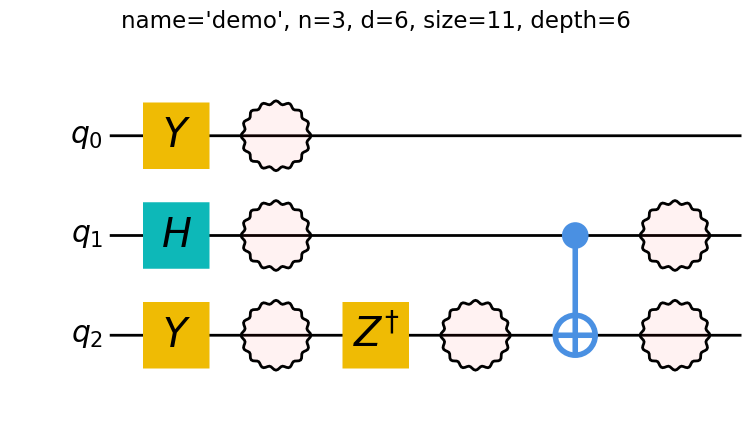

In [11]:
qc2 = qc.copy()

# Insert noise after every (non-noise) operation,
# and after any existing noise blocks (noise stacking)
qc2.add_noise_global(0.05)
qc2.draw(show_info=True)

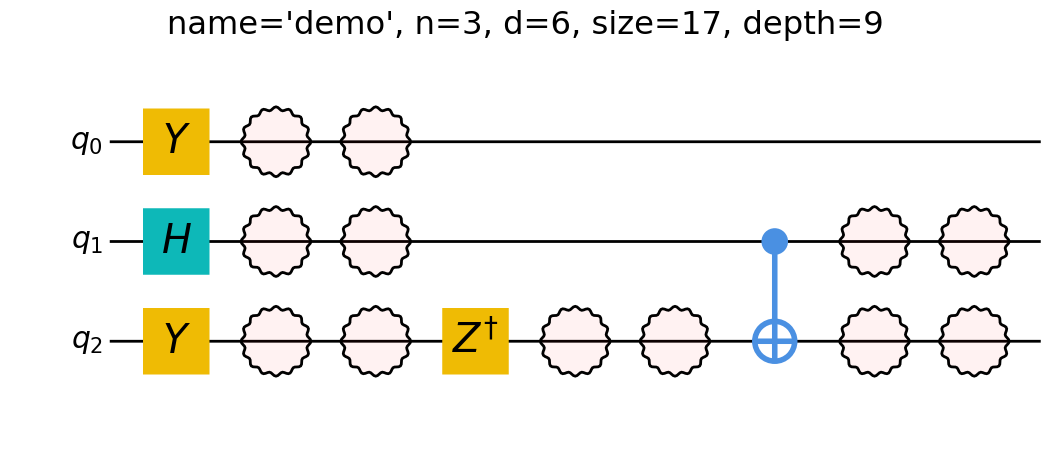

In [12]:
qc21 = qc2.copy()

qc21.add_noise_global(0.05)
qc21.draw(show_info=True)

## Clear noise

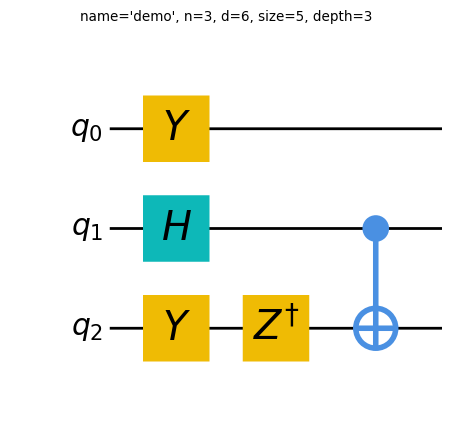

In [13]:
qc211 = qc21.copy()

qc211.clear_noise()
qc211.draw(show_info=True)

## Custom noise model

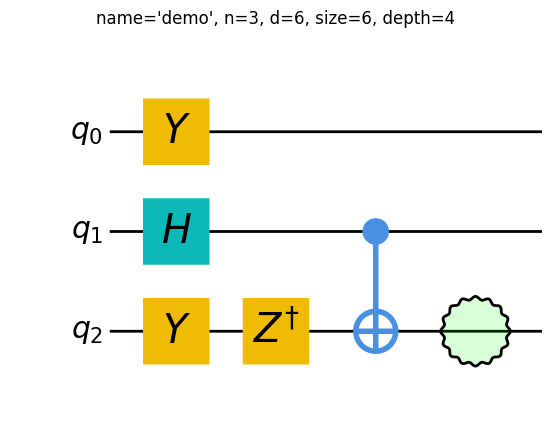

In [14]:
qc3 = qc.copy()

P = np.zeros((d, d), dtype=float)
P[0, 0] = 0.85          # no error
P[1, 0] = 0.10          # W_{1,0} error
P[0, 1] = 0.05          # W_{0,1} error
# (any leftover probability mass would be normalized, here it already sums to 1)

# it's also possible to set custom colors on each noise channel
qc3.add_noise_channel(qudit=2, noise_model=P, color="#00FF00")
qc3.draw(show_info=True)

## Add a noise layer

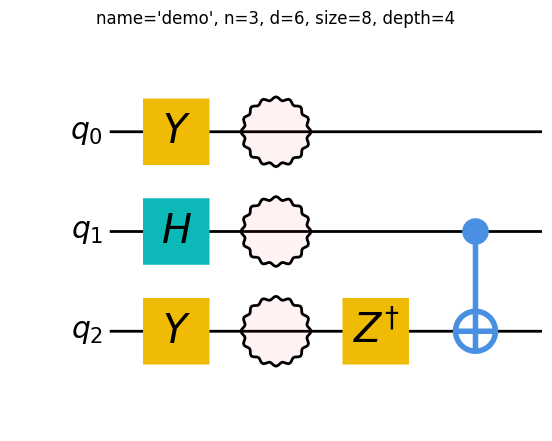

In [15]:
qc4 = qc.copy()

# Insert a full noise layer
qc4.add_noise_layer(
    layer_index=0,
    noise_model=0.05,
    mode="packed",
    where="after",
    include_idle=True,
    in_place=True,
)

qc4.draw(show_info=True)


## Insert noise by visual coordinates (qudit, column)

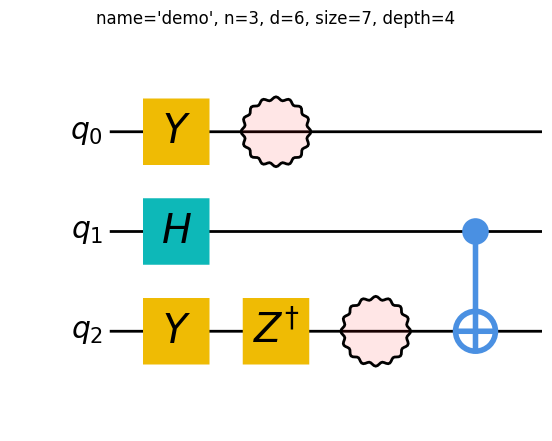

In [16]:
qc5 = qc.copy()

qc5.insert_noise_at_coords(
    coords=[(0, 1), (2, 2)],
    noise_model=0.1,
    in_place=True,
)

qc5.draw(show_info=True)


## Realize noise (sample concrete Weyl errors and replace placeholders)

num realized non-identity errors: 2
first few realized errors: [(Gate(name='W_2,1', n_qudits=1), 0, 1, (2, 1)), (Gate(name='W_3,4', n_qudits=1), 2, 6, (3, 4))]


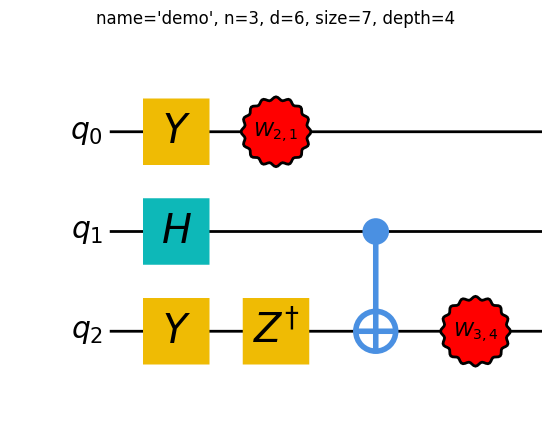

In [17]:
qc6 = qc.copy()
qc6.add_noise_global(0.5)

# Replace NoiseChannel placeholders by sampled Weyl gates W_{a,b}
applied = qc6.realize_noise(seed=123, show_identities=False, in_place=True)

print("num realized non-identity errors:", len(applied))
print("first few realized errors:", applied[:5])

qc6.draw(show_info=True)

## Push noise to the end/start

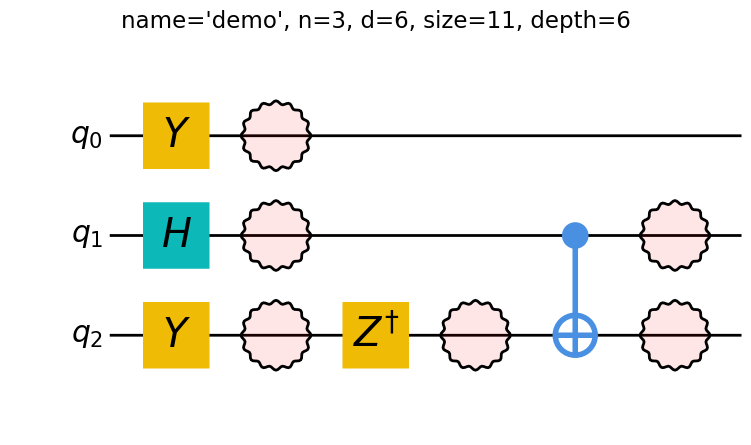

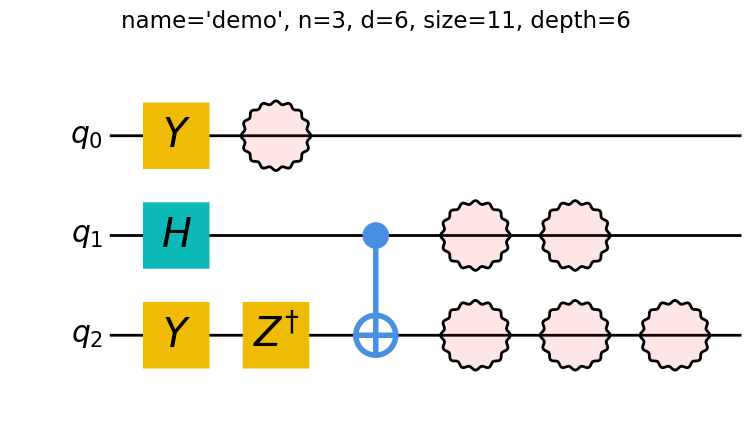

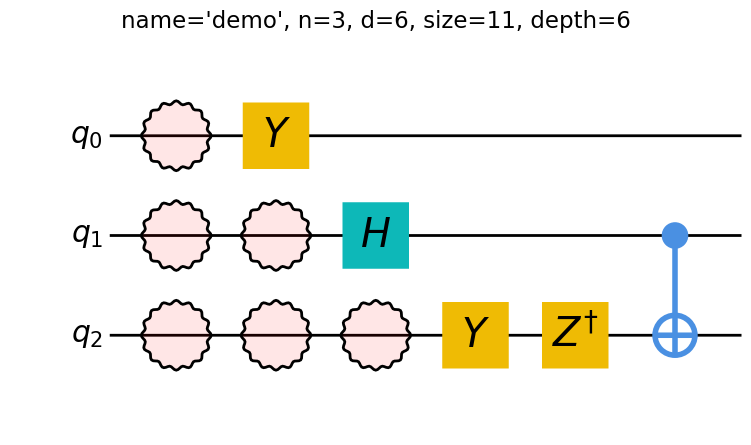

In [18]:
qc7 = qc.copy()
qc7.add_noise_global(0.1)

qc7_end = qc7.push_noise(end=True, in_place=False)
qc7_start = qc7.push_noise(end=False, in_place=False)

qc7.draw(show_info=True)
qc7_end.draw(show_info=True)
qc7_start.draw(show_info=True)

## How to simulate noise

**DM simulation**

In [19]:
n_small, d_small = 2, 4
qc_small = qq.utils.random_circuit(n_small, d_small, max_size=8, max_depth=8, seed=0)
qc_small.add_noise_global(0.2)

rho = qc_small.execute_density_matrix()
p_dm = qq.utils.density_matrix_to_probvector(rho)
print("p_dm sum:", p_dm.sum())


p_dm sum: 0.9999999999999992


**Tableau simulation**

In [20]:
# Prime d -> Tableau, composite d -> CompositeTableau
tab = qq.CompositeTableau(n_small, d_small, full=True)
tab.apply_circuit(qc_small)

p_pf = tab.to_probvector_noisy_pf(qc_small, shots=1_000_000, seed=1)

print("PF vs DM:", np.allclose(p_pf, p_dm, atol=1e-3, rtol=0))

PF vs DM: True


In [21]:
p_pf

array([0.03086 , 0.031035, 0.03703 , 0.054978, 0.03112 , 0.037356,
       0.031146, 0.055019, 0.037477, 0.030853, 0.031004, 0.055126,
       0.103891, 0.103931, 0.103995, 0.225179])

In [22]:
p_dm

array([0.03104639, 0.03104639, 0.0371998 , 0.0549653 , 0.03104639,
       0.0371998 , 0.03104639, 0.0549653 , 0.0371998 , 0.03104639,
       0.03104639, 0.0549653 , 0.10409783, 0.10409783, 0.10409783,
       0.22493285])